# 🧪 [데이터 분석 실습] 화학 공정 센서 데이터를 활용한 이상치 탐지

## 1. 실습 배경 및 목적 (Introduction)
실제 화학 플랜트에서는 수십, 수백 개의 센서(온도, 압력, 유량, 농도 등)가 24시간 내내 운전 데이터를 기록합니다. 공정 엔지니어의 핵심 역할 중 하나는 이 방대한 시계열 데이터 속에서 **설비 고장이나 운전 이상 신호를 조기에 포착하고 원인을 규명**하는 것입니다.

본 실습에서는 화학공학 공정 제어 및 이상 진단 분야의 세계적인 표준 벤치마크인 **Tennessee Eastman Process (TEP)** 시뮬레이션 데이터를 활용하여, 파이썬(`Pandas`, `Matplotlib`, `Seaborn`)으로 실제 공정 트러블을 분석하는 전 과정을 경험합니다.

---

<img src=https://i.postimg.cc/9MmCS68f/ban-eung-naeng-gagsu.jpg, width=600>

## 2. 공정 및 데이터셋 개요 (Dataset Overview)
* **대상 공정:** 기체 반응물을 반응시켜 액체 제품을 생산하는 연속 화학 플랜트(반응기-응축기-분리기-증류탑 구조)
* **시나리오 :** 정상 운전 중 **반응기 냉각수 입구 온도에 갑작스러운 계단 변화(Step Change) 고장**이 발생한 상황
* **수집 주기:** **3분 간격** 시계열 데이터
* **주요 분석 변수 (4개 핵심 지표):**
  1. `React_P`: 반응기 내부 압력 (kPa) — *정상 운전 약 2,705 kPa*
  2. `React_T`: 반응기 내부 온도 (°C) — *정상 운전 약 120.4 °C (핵심 제어 변수)*
  3. `Cool_T`: 반응기 냉각수 출구 온도 (°C) — *정상 운전 약 94.6 °C*
  4. `Prod_Purity`: 최종 제품 G의 순도 (mol%) — *정상 운전 약 53.7 % (최종 품질 지표)*

---

## 3. 실습 진행 로드맵 (Workflow)
이번 실습에서는 트러블 발생 시점(`운전 시작 후 1시간 뒤`)이 알려진 학습 데이터를 활용하여 아래 순서대로 데이터를 탐색하고 분석합니다.

1. **시각적 탐색 (Boxplot & Line Plot):** 전체 변수의 분포와 시간 흐름에 따른 공정 거동을 그래프로 확인합니다.
2. **통계적 이상치 탐지 (IQR 기법):** 사분위수 범위(IQR)를 계산해 정상 범위를 벗어난 이상치(Outlier) 구간과 시점을 추출합니다.
3. **공학적 원인 및 제어 거동 해석:** 냉각수 이상 발생 시 반응기 온도와 최종 제품 순도가 어떻게 반응하는지 공정 제어 관점에서 해석합니다.


In [1]:
import pandas as pd
url = 'https://github.com/KimPandas/cnu/blob/main/files/1.csv?raw=true'
df = pd.read_csv(url, index_col=0, parse_dates=['Timestamp'])
df

,React_P,React_T,Cool_T,Prod_Purity
Timestamp,,,,
2026-11-25 09:00:00,2704.3,120.41,94.640,53.724
2026-11-25 09:03:00,2705.0,120.41,94.595,53.724
2026-11-25 09:06:00,2706.2,120.42,94.605,53.724
2026-11-25 09:09:00,2707.2,120.39,94.473,53.724
2026-11-25 09:12:00,2705.1,120.39,94.678,53.724
...,...,...,...,...
2026-11-26 09:45:00,2707.1,120.40,94.595,53.298
2026-11-26 09:48:00,2704.1,120.40,94.570,53.298
2026-11-26 09:51:00,2700.2,120.39,94.598,53.298


**각 열의 공학적 설명**

Tennessee Eastman Process(TEP)는 기체 반응물을 반응시켜 액체 제품을 생산하는 실제 화학 플랜트 공정입니다. 
각 열은 공정의 핵심 운전 지표를 나타냅니다.

- Timestamp: 3분 간격의 시간 기록입니다.
- React_P (반응기 압력, kPa): 반응이 일어나는 반응기 내부 압력입니다. 정상 운전 시 약 2,705 kPa(약 27 bar) 부근에서 유지됩니다.
- React_T (반응기 온도, °C): 반응기 내부 온도입니다. 발열 반응이므로 냉각수로 열을 식혀주며 약 120.4°C로 정밀하게 제어됩니다.
- Cool_T (반응기 냉각수 출구 온도, °C): 반응기의 반응열을 식히고 나오는 냉각수의 온도입니다. 정상 시 약 94.6°C 부근입니다.
- Prod_Purity (최종 제품 순도/몰분율, mol%): 최종 생산된 액체 흐름 중 목표 주제품인 성분 비율(%)입니다. 약 53.72% 수준으로 생산되며, 공정의 최종 성적표(품질 지표)에 해당합니다.

React_P           Axes(0.125,0.11;0.168478x0.77)
React_T        Axes(0.327174,0.11;0.168478x0.77)
Cool_T         Axes(0.529348,0.11;0.168478x0.77)
Prod_Purity    Axes(0.731522,0.11;0.168478x0.77)
dtype: object

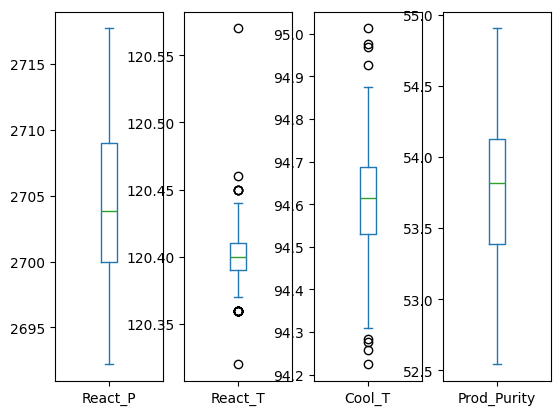

In [2]:
# 간단히 박스 플롯으로 이상치 확인
df.plot(kind='box', subplots=True)

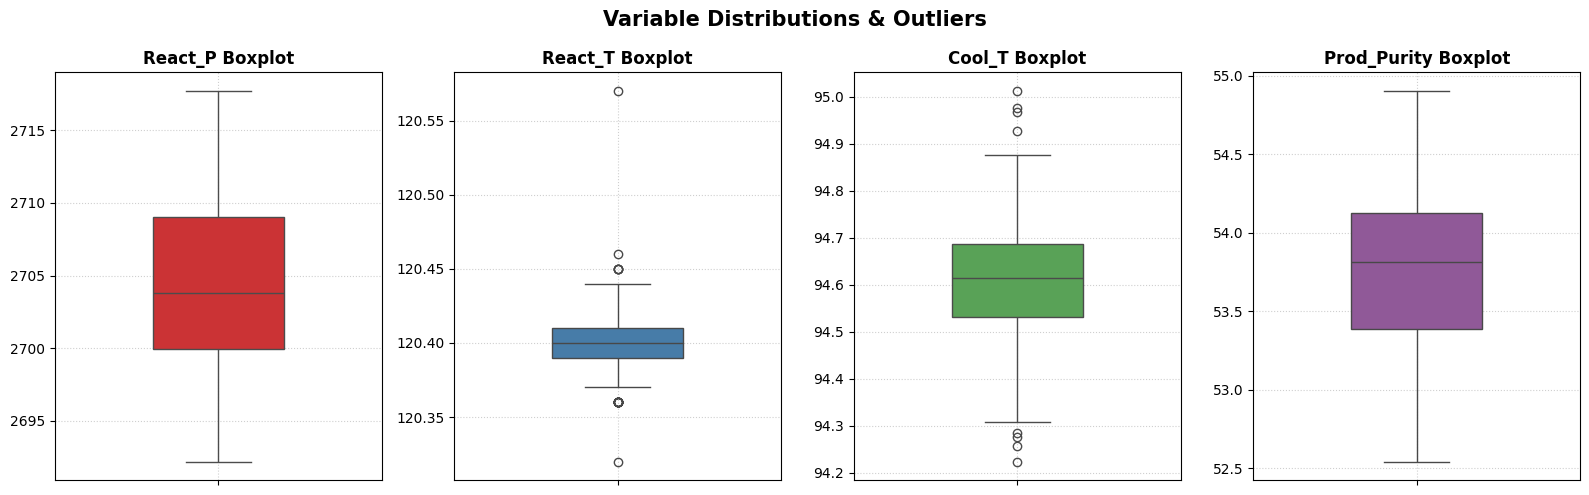

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# 모든 변수 박스플롯 시각화
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 5))
colors = sns.color_palette('Set1', len(df.columns))

for ax, col, color in zip(axes, df.columns, colors):
    sns.boxplot(y=df[col], ax=ax, color=color, width=0.4)
    ax.set_title(f'{col} Boxplot', fontsize=12, fontweight='bold')
    ax.set_ylabel('')
    ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Variable Distributions & Outliers', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# 간단히 각 컬럼별 IQR 기반 이상치 개수 탐지
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

cond1 = df < (Q1 - 1.5 * IQR)
cond2 = df > (Q3 + 1.5 * IQR)
(cond1 | cond2).sum()

React_P         0
React_T        23
Cool_T          8
Prod_Purity     0
dtype: int64

In [5]:
# 각 컬럼별 IQR 기반 이상치 개수 탐지
print('=== [1단계] 컬럼별 IQR 이상치 탐지 결과 ===')
print(f'전체 데이터 행 수: {len(df):,}개')

for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # 정상 범위를 벗어난 행 추출
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    n = len(outliers)
    print(f'\n▶ 변수명: {col}')
    print(f'  - 정상 허용 범위: {lower_bound:.3f} ~ {upper_bound:.3f}')
    print(f'  - 탐지된 이상치 개수: {n}개')
    if n > 0:
        print(f'  - 이상치 발생 시간(최초 3건): {list(outliers.index[:min(3, n)])}')

=== [1단계] 컬럼별 IQR 이상치 탐지 결과 ===
전체 데이터 행 수: 500개

▶ 변수명: React_P
  - 정상 허용 범위: 2686.438 ~ 2722.538
  - 탐지된 이상치 개수: 0개

▶ 변수명: React_T
  - 정상 허용 범위: 120.360 ~ 120.440
  - 탐지된 이상치 개수: 23개
  - 이상치 발생 시간(최초 3건): [Timestamp('2026-11-25 10:00:00'), Timestamp('2026-11-25 10:03:00'), Timestamp('2026-11-25 10:06:00')]

▶ 변수명: Cool_T
  - 정상 허용 범위: 94.296 ~ 94.922
  - 탐지된 이상치 개수: 8개
  - 이상치 발생 시간(최초 3건): [Timestamp('2026-11-25 09:45:00'), Timestamp('2026-11-25 11:18:00'), Timestamp('2026-11-25 12:03:00')]

▶ 변수명: Prod_Purity
  - 정상 허용 범위: 52.280 ~ 55.239
  - 탐지된 이상치 개수: 0개


array([[<Axes: xlabel='Timestamp'>],
       [<Axes: xlabel='Timestamp'>],
       [<Axes: xlabel='Timestamp'>],
       [<Axes: xlabel='Timestamp'>]], dtype=object)

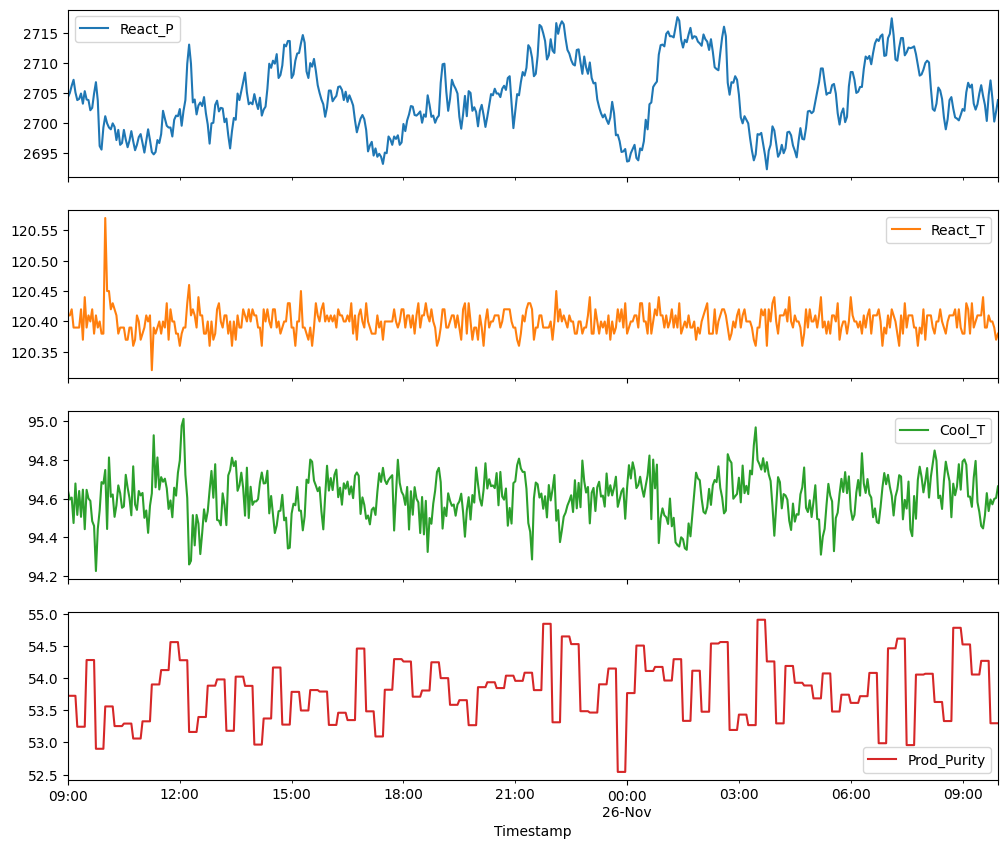

In [6]:
# 간단히 변수 전체 시계열 라인 그래프 시각화
df.plot(subplots=True, layout=(4, 1), figsize=(12, 10))

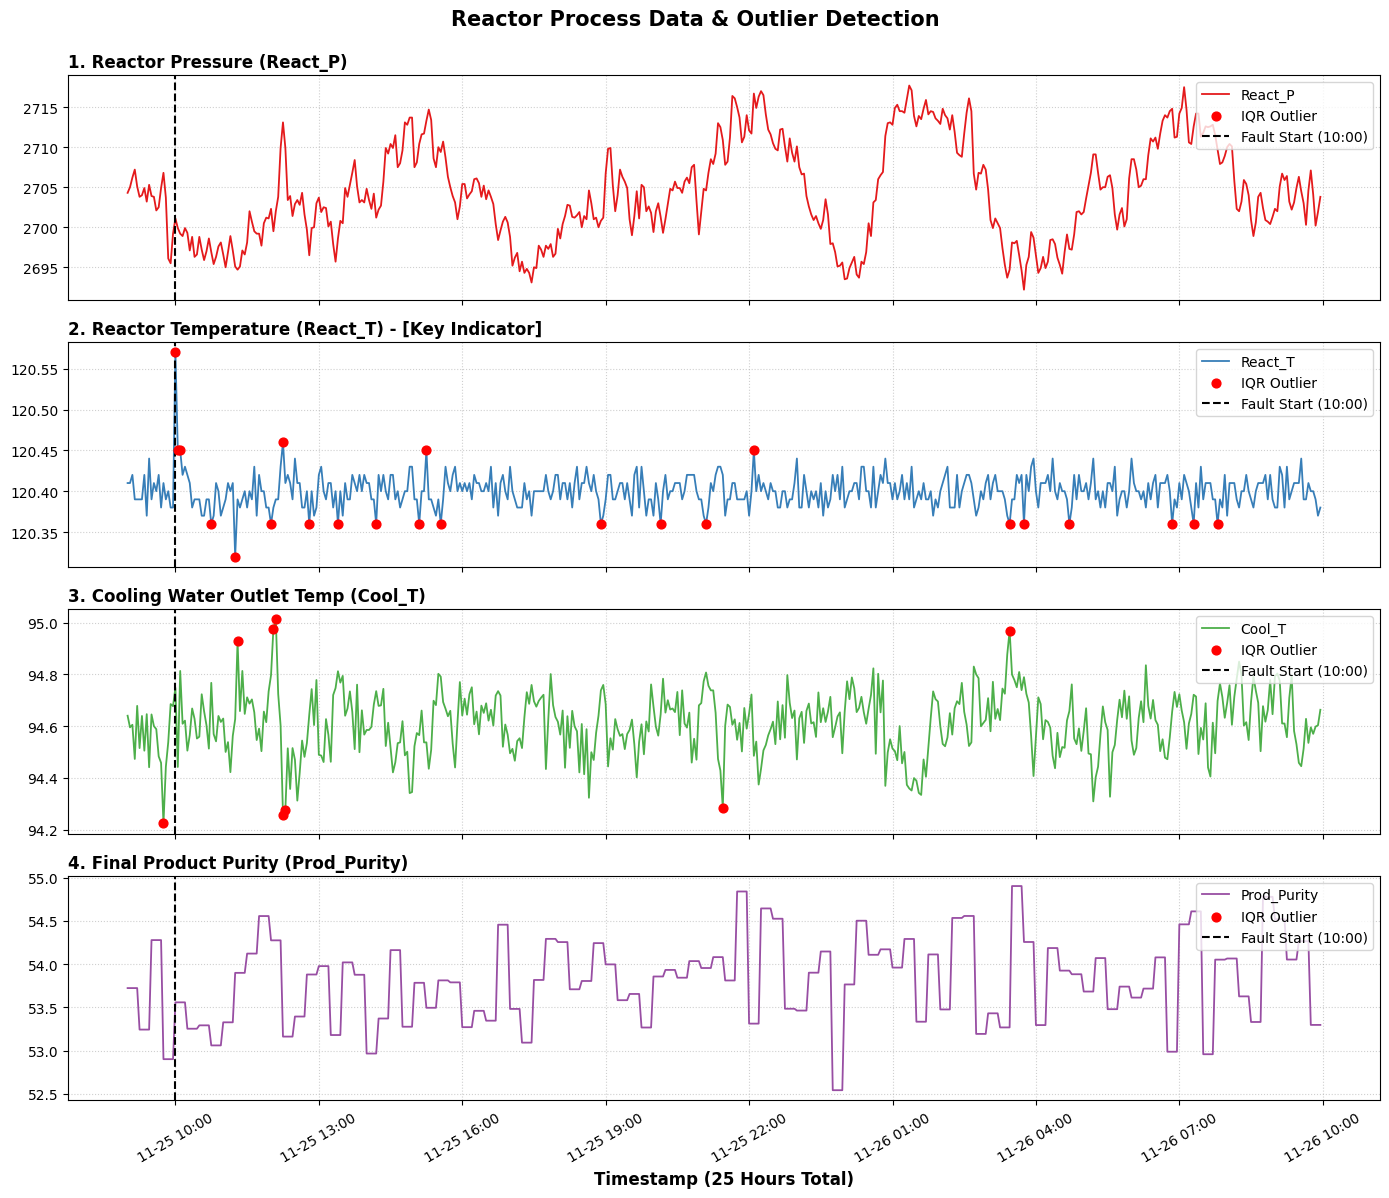

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

# 변수 전체 시계열 라인 그래프 시각화
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)

# Training 데이터의 고장 발생 시각 (시작 후 1시간 뒤 = 10:00)
fault_time = pd.Timestamp('2026-11-25 10:00:00')

titles = [
    '1. Reactor Pressure (React_P)',
    '2. Reactor Temperature (React_T) - [Key Indicator]',
    '3. Cooling Water Outlet Temp (Cool_T)',
    '4. Final Product Purity (Prod_Purity)'
]

colors = sns.color_palette('Set1', len(df.columns))
for ax, col, title, color in zip(axes, df.columns, titles, colors):
    # 기본 라인 그래프
    ax.plot(df.index, df[col], color=color, linewidth=1.3, label=col)
    
    # IQR 이상치 계산 후 빨간 점으로 강조 표시
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    ax.scatter(outliers.index, outliers[col], color='red', zorder=5, s=40, label='IQR Outlier')
    
    # 고장 발생 시점(10:00) 검은색 점선 표시
    ax.axvline(fault_time, color='black', linestyle='--', linewidth=1.5, label='Fault Start (10:00)')
    
    ax.set_title(title, fontsize=12, fontweight='bold', loc='left')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right')

# X축 시간 포맷 설정 (3시간 간격 눈금)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=3))
plt.xticks(rotation=30)
axes[-1].set_xlabel('Timestamp (25 Hours Total)', fontsize=12, fontweight='bold')

plt.suptitle('Reactor Process Data & Outlier Detection', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 📊 공정 트러블 학습 데이터 분석 리포트

### 1. 분석 개요
* **분석 대상:** Tennessee Eastman Process (TEP) 25시간 운전 데이터 (`df`, 3분 간격 500샘플)
* **시나리오:** 반응기 냉각수 입구 온도 변화
* **트러블 발생 시점:** 운전 시작 1시간 후 (`11-25 10:00`, 그래프 내 검은색 수직 점선)

---

### 2. 주요 변수별 시계열 거동 및 이상치(IQR) 분석

* **① 반응기 온도 (`React_T`, 2번 그래프) — [가장 명확한 트러블 탐지 지표]**
  * **거동:** `11-25 10:00` 점선 직후, 정상 운전 범위(120.36°C ~ 120.44°C)를 크게 벗어나는 약 **120.57°C의 급격한 피크(Spike) 이상치**가 관측됩니다.
  * **이상치 해석:** IQR 기준으로 총 23개의 빨간 점이 찍혔으나, 대부분은 120.35°C나 120.45°C 부근에서 발생하는 미세한 센서 노이즈(오경보)입니다. 반면 고장 발생 직후(10:00~10:06)에 찍힌 120.57°C 피크는 압도적인 크기를 보이므로 **진짜 공정 트러블을 구분하는 핵심 신호가 됩니다.**

* **② 반응기 압력 (`React_P`, 1번 그래프) — [정상 범위 내 주기적 변동]**
  * **거동:** 압력은 2693 ~ 2718 kPa 사이에서 완만한 주기성을 그리며 움직이며, IQR 기준을 벗어난 이상치는 0건입니다. 10:00 고장 발생 직후 약 2695 kPa 부근으로 소폭 하강하는 모습이 보이나 정상 운전 변동 폭 내에 머물렀습니다.

* **③ 냉각수 출구 온도 (`Cool_T`, 3번 그래프) — [제어기 보상 작용으로 인한 방어]**
  * **거동:** 94.2°C ~ 95.0°C 범위에서 진동하며 총 8개의 IQR 이상치가 탐지되었으나, 고장 발생 시점(10:00)과 무관하게 전 구간에 흩어져 있습니다.
  * **공학적 해석:** 유입되는 냉각수 온도에 이상이 생겼음에도 출구 온도가 일정하게 유지되는 이유는, 자동 제어기(PID)가 냉각수 유량 밸브를 조절해 총 제거 열량을 일정하게 방어했기 때문입니다.

* **④ 최종 제품 순도 (`Prod_Purity`, 4번 그래프) — [품질 영향 없음]**
  * **거동:** 제품 순도는 52.5 ~ 54.9% 범위에서 계단식(분석기 샘플링 주기)으로 변동하며 IQR 이상치는 0건입니다. 트러블 발생 이후에도 최종 제품 품질에는 타격이 없었습니다.

---

### 3. 종합 결론 및 다음 단계(Test 데이터 탐지) 전략

1. **핵심 탐지 변수 선정:** 4개의 공정 변수 중 고장 발생 시점(10:00)을 가장 정확하게 포착하는 지표는 `React_T`(반응기 온도)입니다.
2. **오경보(False Alarm) 제거 전략:** `React_T`에서 단순히 `1.5 * IQR` (120.44°C) 기준만 적용하면 정상 구간 노이즈(120.45°C)까지 이상치로 잡히는 한계가 있습니다.
3. **실전 탐지 기준 수립:** 따라서 Test 데이터에서 고장 발생 시각을 정확히 찾아낼 때는 초기 1시간 정상 구간의 `React_T` 데이터를 기준으로 삼되, **IQR 배수를 3.0 이상으로 높이거나 120.50°C 이상의 임계값**을 설정하면 오경보 없이 정확한 트러블 시작 시각만 깔끔하게 추출할 수 있습니다.

---
실행 결과(출력값과 그래프)가 저장된 .ipynb 파일을 업로드한 뒤, 아래 프롬프트를 입력해 표준화된 분석 결과 리포트를 얻을 수 있습니다.

```
첨부한 .ipynb 파일의 코드, 출력 수치, 그리고 시각화 그래프를 종합적으로 분석하여 [표준 데이터 분석 결과 리포트]를 작성해 줘.

단순한 코드 설명은 배제하고, 아래 5가지 표준 분석 프레임워크에 맞춰 명확한 근거 수치와 함께 마크다운 형식으로 정리해 줘.

1. 분석 개요 및 데이터 정제 요약
   - 분석 목적, 데이터 규모, 결측치 및 이상치 처리 등 분석 신뢰도를 뒷받침하는 전처리 핵심 요약
2. 주요 변수 기초 통계 및 분포 특성
   - 핵심 변수들의 정상 범위, 평균·중앙값·변동성(분산) 등 전반적인 데이터 프로파일
3. 핵심 패턴 및 특이 현상 (인사이트 도출)
   - 그래프와 통계에서 드러나는 가장 뚜렷한 추세, 집단 간 차이, 또는 특이점(이상치) 발생 양상
4. 변수 간 상관관계 및 핵심 영향 요인
   - 목표 변수(결과)에 가장 큰 영향을 미치는 주요 변수와 관계의 방향성(양·음의 관계, 비선형성 등)
5. 종합 결론 및 향후 제언 (Action Item)
   - 분석 결과를 통해 내릴 수 있는 최종 결론, 현재 데이터의 한계점, 및 다음 단계 분석·실무 적용 방향
```

- ChatGPT 결과 예시: https://chatgpt.com/s/t_6b069d68f3308191a4ec44ad6aba9622